C:\Users\SUBHADEEP\AppData\Local\Temp\ipykernel_6296\791303427.py:14: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = list(df.select_dtypes(include=['object']).columns)


--- Question 1 ---
lead_score: 0.7882
number_of_courses_viewed: 0.7230
interaction_count: 0.7649
annual_income: 0.6082
-> Choose the feature with the highest score printed above.

--- Question 2 ---
Validation AUC: 0.732

--- Question 3 ---


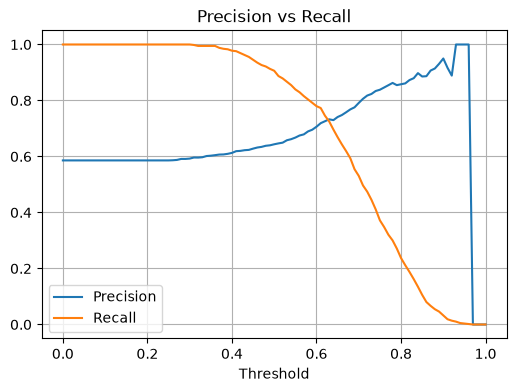

Intersection threshold: 0.63

--- Question 4 ---
Max F1 threshold: 0.41

--- Question 5 ---
Standard deviation of AUCs: 0.007

--- Question 6 ---
C=1e-06      | mean_auc=0.617 | std_auc=0.019
C=0.001      | mean_auc=0.749 | std_auc=0.010
C=1          | mean_auc=0.732 | std_auc=0.007
-> Choose the 'C' with the highest mean_auc (in case of a tie, choose the one with the lowest std_auc, and if still tied, smallest C).


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression


df = pd.read_csv('data_score.csv')


categorical_cols = list(df.select_dtypes(include=['object']).columns)
numerical_cols = list(df.select_dtypes(exclude=['object']).columns)

if 'converted' in categorical_cols:
    categorical_cols.remove('converted')
if 'converted' in numerical_cols:
    numerical_cols.remove('converted')

df[categorical_cols] = df[categorical_cols].fillna('NA')
df[numerical_cols] = df[numerical_cols].fillna(0.0)

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train['converted'].values
y_val = df_val['converted'].values
y_test = df_test['converted'].values

df_train.drop('converted', axis=1, inplace=True)
df_val.drop('converted', axis=1, inplace=True)
df_test.drop('converted', axis=1, inplace=True)

# ---------------------------------------------------------
# QUESTION 1: ROC AUC feature importance
# ---------------------------------------------------------
print("--- Question 1 ---")
features_to_test = ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']

for col in features_to_test:
    auc = roc_auc_score(y_train, df_train[col])
    # Invert correlation if AUC < 0.5
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
    print(f"{col}: {auc:.4f}")
print("-> Choose the feature with the highest score printed above.\n")

# ---------------------------------------------------------
# QUESTION 2: Training the model
# ---------------------------------------------------------
print("--- Question 2 ---")
dv = DictVectorizer(sparse=False)

train_dicts = df_train.to_dict(orient='records')
X_train = dv.fit_transform(train_dicts)

val_dicts = df_val.to_dict(orient='records')
X_val = dv.transform(val_dicts)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred_val = model.predict_proba(X_val)[:, 1]
auc_val = roc_auc_score(y_val, y_pred_val)
print(f"Validation AUC: {auc_val:.3f}\n")

# ---------------------------------------------------------
# QUESTION 3: Precision and Recall
# ---------------------------------------------------------
print("--- Question 3 ---")
thresholds = np.linspace(0, 1, 101) # 0.0 to 1.0 with step 0.01
precisions, recalls = [], []

for t in thresholds:
    predict_pos = (y_pred_val >= t)
    
    tp = ((predict_pos) & (y_val == 1)).sum()
    fp = ((predict_pos) & (y_val == 0)).sum()
    fn = ((~predict_pos) & (y_val == 1)).sum()
    
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    
    precisions.append(p)
    recalls.append(r)

# Plotting
plt.figure(figsize=(6, 4))
plt.plot(thresholds, precisions, label='Precision')
plt.plot(thresholds, recalls, label='Recall')
plt.legend()
plt.xlabel('Threshold')
plt.title('Precision vs Recall')
plt.grid(True)
plt.show()

diffs = [abs(p - r) for p, r in zip(precisions, recalls)]
valid_idx = [i for i, (p, r) in enumerate(zip(precisions, recalls)) if p > 0 or r > 0]
best_t_q3 = thresholds[min(valid_idx, key=lambda i: diffs[i])]

print(f"Intersection threshold: {best_t_q3:.2f}\n")

# ---------------------------------------------------------
# QUESTION 4: F1 score
# ---------------------------------------------------------
print("--- Question 4 ---")
f1_scores = []
for p, r in zip(precisions, recalls):
    if p + r == 0:
        f1_scores.append(0)
    else:
        f1_scores.append(2 * p * r / (p + r))

best_t_q4 = thresholds[np.argmax(f1_scores)]
print(f"Max F1 threshold: {best_t_q4:.2f}\n")

# ---------------------------------------------------------
# QUESTION 5: 5-Fold CV
# ---------------------------------------------------------
print("--- Question 5 ---")
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
aucs = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train_cv = df_full_train.iloc[train_idx].copy()
    df_val_cv = df_full_train.iloc[val_idx].copy()
    
    y_train_cv = df_train_cv['converted'].values
    y_val_cv = df_val_cv['converted'].values
    
    df_train_cv.drop('converted', axis=1, inplace=True)
    df_val_cv.drop('converted', axis=1, inplace=True)
    
    dv_cv = DictVectorizer(sparse=False)
    X_train_cv = dv_cv.fit_transform(df_train_cv.to_dict(orient='records'))
    X_val_cv = dv_cv.transform(df_val_cv.to_dict(orient='records'))
    
    model_cv = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model_cv.fit(X_train_cv, y_train_cv)
    
    y_pred_cv = model_cv.predict_proba(X_val_cv)[:, 1]
    aucs.append(roc_auc_score(y_val_cv, y_pred_cv))

print(f"Standard deviation of AUCs: {np.std(aucs):.3f}\n")

# ---------------------------------------------------------
# QUESTION 6: Hyperparameter Tuning
# ---------------------------------------------------------
print("--- Question 6 ---")
for C in [0.000001, 0.001, 1]:
    aucs = []
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    
    for train_idx, val_idx in kfold.split(df_full_train):
        df_train_cv = df_full_train.iloc[train_idx].copy()
        df_val_cv = df_full_train.iloc[val_idx].copy()
        
        y_train_cv = df_train_cv['converted'].values
        y_val_cv = df_val_cv['converted'].values
        
        df_train_cv.drop('converted', axis=1, inplace=True)
        df_val_cv.drop('converted', axis=1, inplace=True)
        
        dv_cv = DictVectorizer(sparse=False)
        X_train_cv = dv_cv.fit_transform(df_train_cv.to_dict(orient='records'))
        X_val_cv = dv_cv.transform(df_val_cv.to_dict(orient='records'))
        
        model_cv = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        model_cv.fit(X_train_cv, y_train_cv)
        
        y_pred_cv = model_cv.predict_proba(X_val_cv)[:, 1]
        aucs.append(roc_auc_score(y_val_cv, y_pred_cv))
        
    print(f"C={C:<10} | mean_auc={np.mean(aucs):.3f} | std_auc={np.std(aucs):.3f}")
print("-> Choose the 'C' with the highest mean_auc (in case of a tie, choose the one with the lowest std_auc, and if still tied, smallest C).")